 ## Data Exploration & Cleaning

In [17]:
import pandas as pd
import numpy as np
# loading initial data
df = pd.read_csv("project_dataset.csv", sep=";")

df.shape
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype 
---  ------                                                                                       --------------  ----- 
 0   Date                                                                                         12010 non-null  object
 1   Service                                                                                      11830 non-null  object
 2   Gare de départ                                                                               12011 non-null  object
 3   Gare d'arrivée                                                                               12011 non-null  object
 4   Durée moyenne du trajet                                                                      11830 non-null  object
 5   Nombre de circulations prévues         

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,12010,11830,12011,12011,11830,11830,11831,577,11830,11831,...,11828,11831,11832,11833,11828,11827,11829,11827,11828,11830
unique,318,2,132,116,651,1034,248,3,629,11162,...,265,11075,175,96,2732,2592,2677,2535,2130,2172
top,2025-09,National,PARIS LYON,PARIS LYON,96.0,31.0,0.0,Non communiqué,13.0,0.0,...,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
freq,135,10370,2405,2413,184,117,3917,196,161,134,...,327,218,779,1760,1100,1021,1326,1220,3361,3809


In [18]:
# identifying columns where there are empty values and in what percentage ratio
missing = df.isna().mean().sort_values(ascending=False)*100
missing
df.isna().sum().sort_values(ascending=False)

Commentaire annulations                                                                        11493
Commentaire retards au départ                                                                  11466
Commentaire retards à l'arrivée                                                                10930
Prct retard pour cause matériel roulant                                                          243
Prct retard pour cause infrastructure                                                            243
Prct retard pour causes externes                                                                 242
Retard moyen des trains en retard à l'arrivée                                                    242
Nombre trains en retard > 15min                                                                  242
Prct retard pour cause gestion en gare et réutilisation de matériel                              242
Prct retard pour cause gestion trafic                                                      

In [19]:
# removing almost empty columns
df = df.drop(columns=[
    "Commentaire annulations",
    "Commentaire retards au départ",
    "Commentaire retards à l'arrivée"
])
# convert date type
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", format="mixed")
df.isna().sum().sort_values(ascending=False)


Prct retard pour cause matériel roulant                                                        243
Prct retard pour cause infrastructure                                                          243
Nombre trains en retard > 15min                                                                242
Retard moyen des trains en retard à l'arrivée                                                  242
Prct retard pour causes externes                                                               242
Prct retard pour cause gestion en gare et réutilisation de matériel                            242
Nombre de trains en retard à l'arrivée                                                         241
Prct retard pour cause gestion trafic                                                          241
Retard moyen de tous les trains au départ                                                      241
Nombre de trains en retard au départ                                                           240
Prct retar

In [20]:
# removing lines where at least one critical value is missing
df = df.dropna(subset=[
    "Retard moyen de tous les trains à l'arrivée",
    "Date",
    "Gare de départ",
    "Gare d'arrivée"
])
# check how many are empty

df.isna().sum().sort_values(ascending=False)

Prct retard pour causes externes                                                               238
Nombre trains en retard > 15min                                                                236
Prct retard pour cause gestion trafic                                                          236
Prct retard pour cause matériel roulant                                                        236
Retard moyen des trains en retard à l'arrivée                                                  235
Retard moyen des trains en retard au départ                                                    235
Nombre de trains en retard à l'arrivée                                                         234
Retard moyen de tous les trains au départ                                                      234
Prct retard pour cause gestion en gare et réutilisation de matériel                            233
Durée moyenne du trajet                                                                        233
Nombre tra

In [32]:
text_cols = ["Date", "Service", "Gare de départ", "Gare d'arrivée"]

# standardize all numerical values to a single format, convert numerical columns to float
for col in df.columns:
    if col not in text_cols:
        df[col]=(df[col].astype(str).str.extract(r'(-?\d+[.,]?\d*)')[0].str.replace(",",".", regex=False))
        df[col]=pd.to_numeric(df[col], errors="coerce")

df.isna().sum().sort_values(ascending=False)
df.dtypes

Date                                                                                           datetime64[ns]
Service                                                                                                object
Gare de départ                                                                                         object
Gare d'arrivée                                                                                         object
Durée moyenne du trajet                                                                               float64
Nombre de circulations prévues                                                                        float64
Nombre de trains annulés                                                                              float64
Nombre de trains en retard au départ                                                                  float64
Retard moyen des trains en retard au départ                                                           float64
Retard moy

In [33]:
# select all columns with type float64
num_col = df.select_dtypes(include=["float64"]).columns

# filling empty values with column mean values
for col in num_col:
    df[col] = df[col].fillna(df[col].mean())

# Filling empty rows in the "Service" column
df["Service"]=df["Service"].fillna("Unknown")

# removing duplicates
df = df.drop_duplicates()

# removing negative numbers
float_cols = df.select_dtypes(include=["float64"]).columns

for col in float_cols:
    df = df[df[col] >= 0]

# Check delay consistency
df = df[
    (df["Nombre trains en retard > 30min"] <= df["Nombre trains en retard > 15min"]) &
    (df["Nombre trains en retard > 60min"] <= df["Nombre trains en retard > 30min"])
]

# Check station pair duplicates
df = df.drop_duplicates(
    subset=["Date", "Gare de départ", "Gare d'arrivée"]
)

df.to_csv('cleaned_dataset.csv', index=False)

## Step 2: Data Visualization & Analysis

In [34]:
df = pd.read_csv("cleaned_dataset.csv")
df.describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,...,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",route,month,effective_trains,delay_rate,cancellation_rate,reconstructed_delay
count,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000,...,10607.000000,10607.000000,10607.000000,10607.000000,10607.0,10607.000000,10607.000000,10607.000000,10607.000000,10607.000000
mean,171.141741,274.954153,8.689097,89.435642,12.440861,3.270789,38.194654,35.452992,6.323096,27.515226,...,20.620737,19.121157,7.399186,7.595429,0.0,6.674649,266.265056,0.150761,0.038163,5.359356
std,86.162051,179.317795,22.397923,90.616435,11.752374,4.405612,30.526781,15.070107,4.181147,22.209225,...,14.374235,13.033435,7.707290,9.152322,0.0,3.416086,176.502221,0.124146,0.083735,4.882117
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000
25%,101.000000,157.000000,0.000000,24.000000,6.460218,1.303556,17.000000,26.209545,3.521224,12.000000,...,11.111111,10.638298,0.000000,0.000000,0.0,4.000000,149.000000,0.093127,0.000000,2.817517
50%,166.000000,236.000000,2.000000,57.000000,10.671759,2.444985,31.000000,33.955956,5.440051,23.000000,...,19.230769,17.647059,6.060606,5.263158,0.0,7.000000,228.000000,0.132353,0.007491,4.399590
75%,222.000000,358.000000,7.000000,128.000000,15.665142,3.964945,51.000000,42.245581,8.183528,37.000000,...,28.571429,25.000000,10.968285,11.111111,0.0,10.000000,342.000000,0.184307,0.032059,6.759935
max,703.130000,1100.000000,297.000000,1066.000000,316.188000,115.047390,274.000000,299.600000,92.000000,221.000000,...,100.000000,100.000000,100.000000,100.000000,0.0,12.000000,1099.000000,6.207516,0.926829,221.918709


In [35]:
df["Retard moyen de tous les trains à l'arrivée"].describe()

count    10607.000000
mean         6.323096
std          4.181147
min          0.000000
25%          3.521224
50%          5.440051
75%          8.183528
max         92.000000
Name: Retard moyen de tous les trains à l'arrivée, dtype: float64

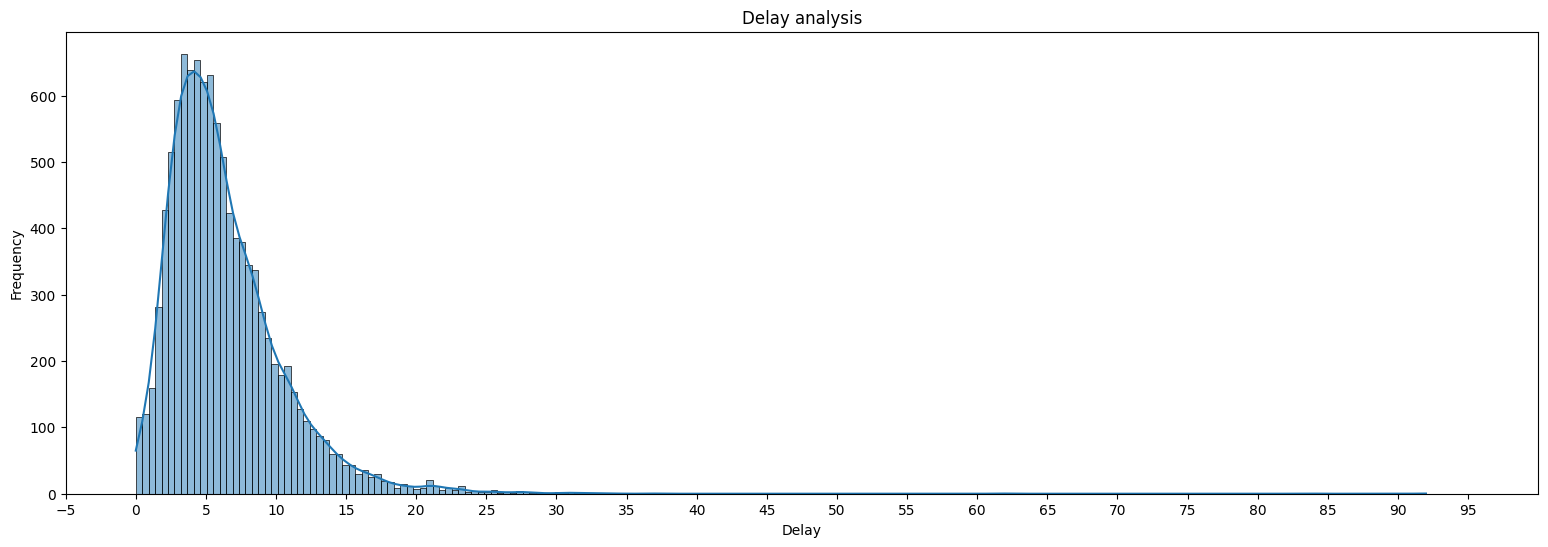

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# create a histogram of the delay distribution
plt.figure(figsize=(19, 6))
sns.histplot(df["Retard moyen de tous les trains à l'arrivée"], bins=200, kde=True)

# set plot title and axis labels
plt.title("Delay analysis")
plt.xlabel("Delay")
plt.ylabel("Frequency")

# limit x-axis range and set tick marks for readability
plt.xlim(-5,100)
plt.xticks(range(-5, 100, 5))

# display the figure
plt.show()

### Interpretation
The distribution of arrival delays is right skewed.  
Most trains experience small delays around 0-10 minutes.  
However, there are some extreme delays reaching up to ~90 minutes.  
This indicates that while the system is generally punctual, rare severe disruptions occur.

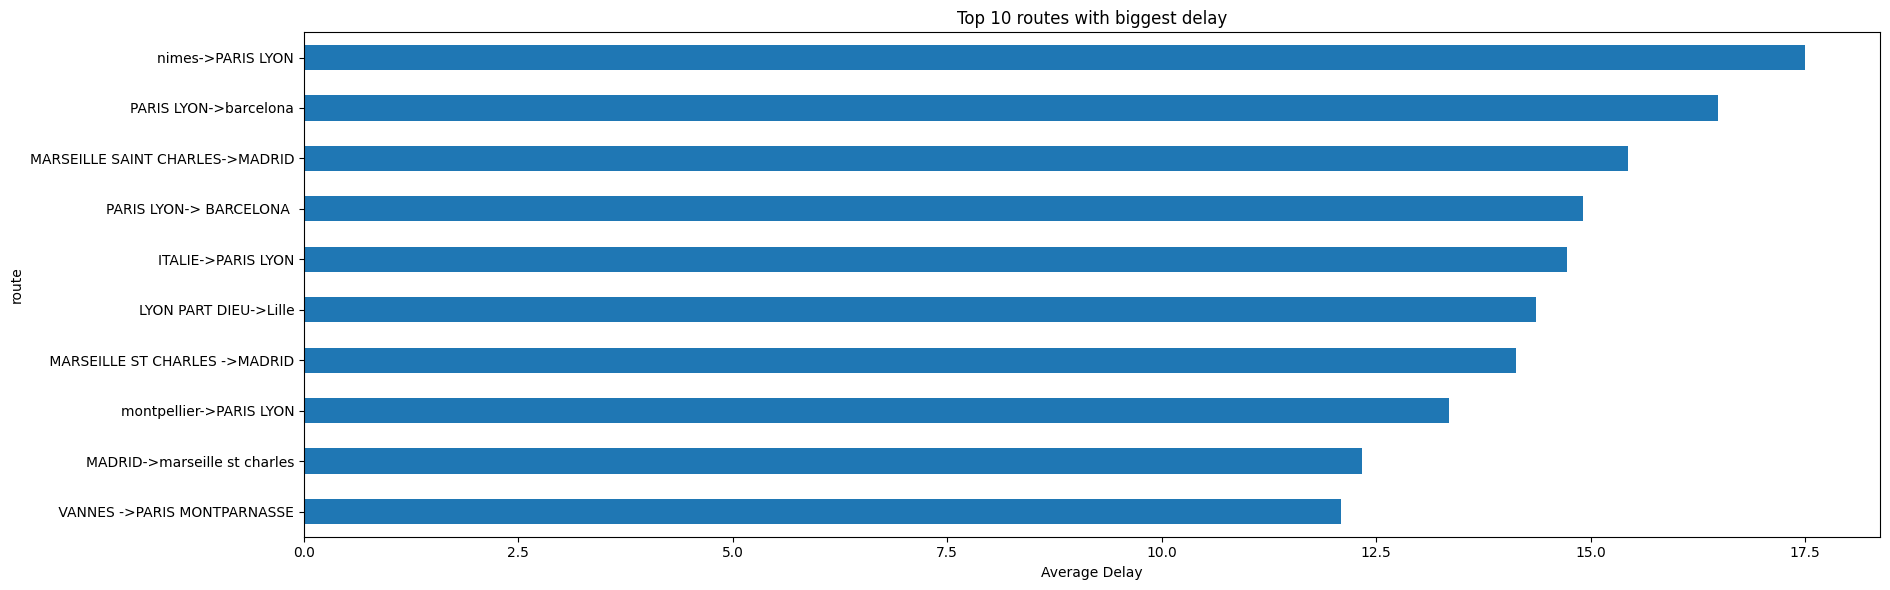

In [37]:
df["route"] = df["Gare de départ"] + "->" + df["Gare d'arrivée"]
# compute average delay per route and pick the top 10
top_routes = df.groupby("route")["Retard moyen de tous les trains à l'arrivée"].mean().sort_values(ascending=False).head(10)

# plot horizontal bar chart of the top routes
plt.figure(figsize=(19,6))
top_routes.sort_values().plot(kind="barh")
plt.xlabel("Average Delay")
plt.title("Top 10 routes with biggest delay")
plt.tight_layout()
plt.show()

### Interpretation
On some routes, delays exceed the average, indicating that this is not a global problem affecting the entire SNCF, but rather structural problems on specific connections.

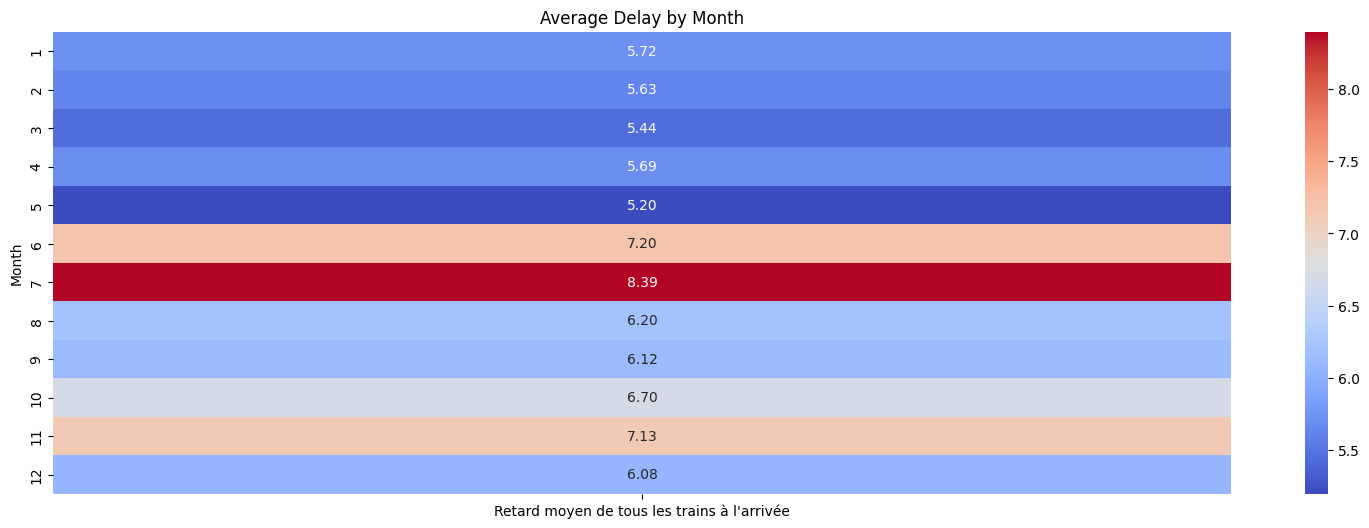

In [38]:
#ensure "Date" is datetime and extract month
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month
#average delay by month
monthly_delay = df.groupby("month")["Retard moyen de tous les trains à l'arrivée"].mean()
#build pivot table for heatmap
pivot_m = df.pivot_table(
    values = "Retard moyen de tous les trains à l'arrivée",
    index = "month",
    aggfunc = "mean"
)
#plot heatmap of monthly average delays
plt.figure(figsize=(19,6))
sns.heatmap(
    pivot_m,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Average Delay by Month")
plt.ylabel("Month")
plt.show()

### Interpretation

The heatmap shows a clear seasonal pattern in average arrival delays.  
Delays remain relatively stable between January and May (around 5-6 minutes).  
However, a significant increase is observed in June and especially July, where the average delay peaks at 8.39 minutes.


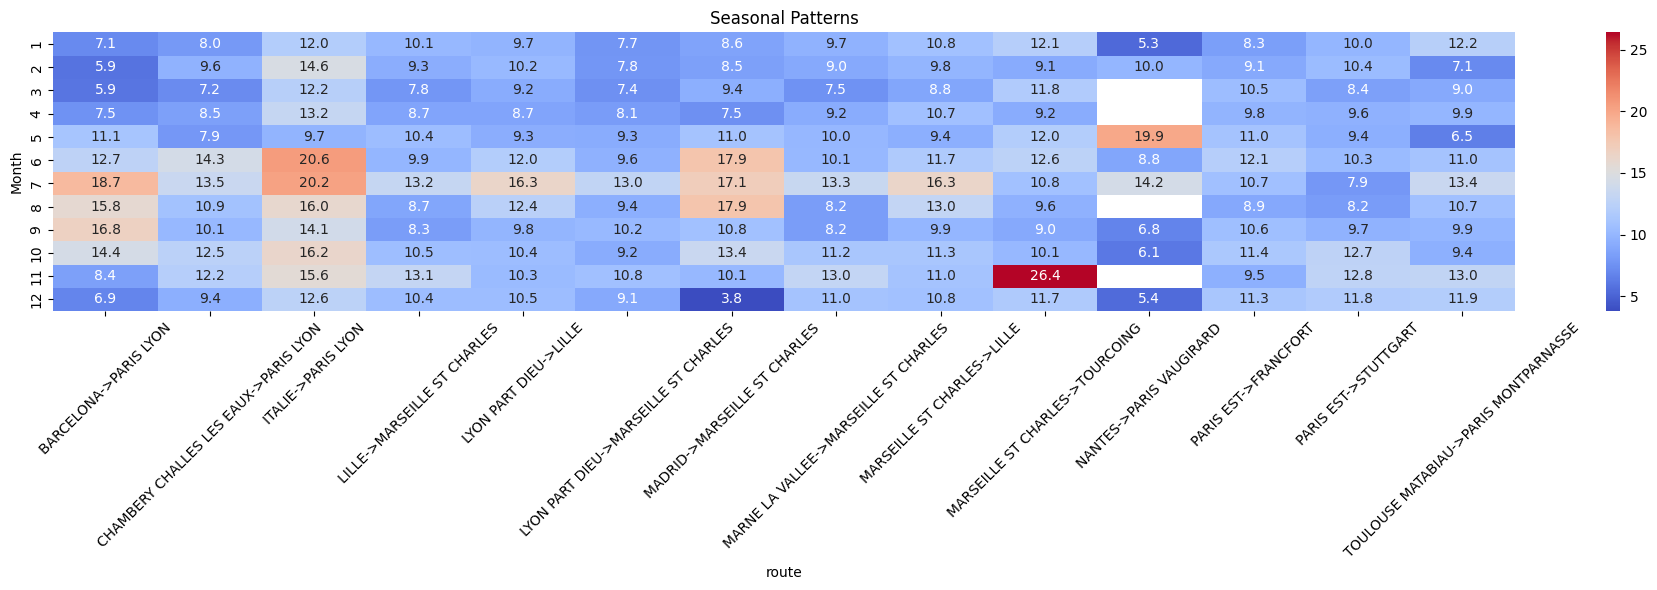

In [39]:
#identify top 50 routes by average delay
top_routes = df.groupby("route")["Retard moyen de tous les trains à l'arrivée"].mean().sort_values(ascending=False).head(50).index
#keep only those observed in at least 6 months
valid_routes = (
    df.groupby("route")["month"].nunique().loc[lambda x: x >= 6].index
)
top_valid_routes = [
    r for r in top_routes
    if r in valid_routes
]

#build pivot table of delays for the selected routes
pivot_comb = df[df["route"].isin(top_valid_routes)].pivot_table(
    values="Retard moyen de tous les trains à l'arrivée",
    index="month",
    columns="route",
    aggfunc="mean")

#plot seasonal heatmap for these routes
plt.figure(figsize=(19,6))
sns.heatmap(
    pivot_comb,
    annot=True,
    cmap="coolwarm",
    fmt=".1f"
)
plt.title("Seasonal Patterns")
plt.ylabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

The heatmap shows a clear seasonal pattern across all routes.
In July, delays increase significantly for every route. This suggests that the rise in delays is not route specific but affects the whole network.


<Figure size 640x480 with 0 Axes>

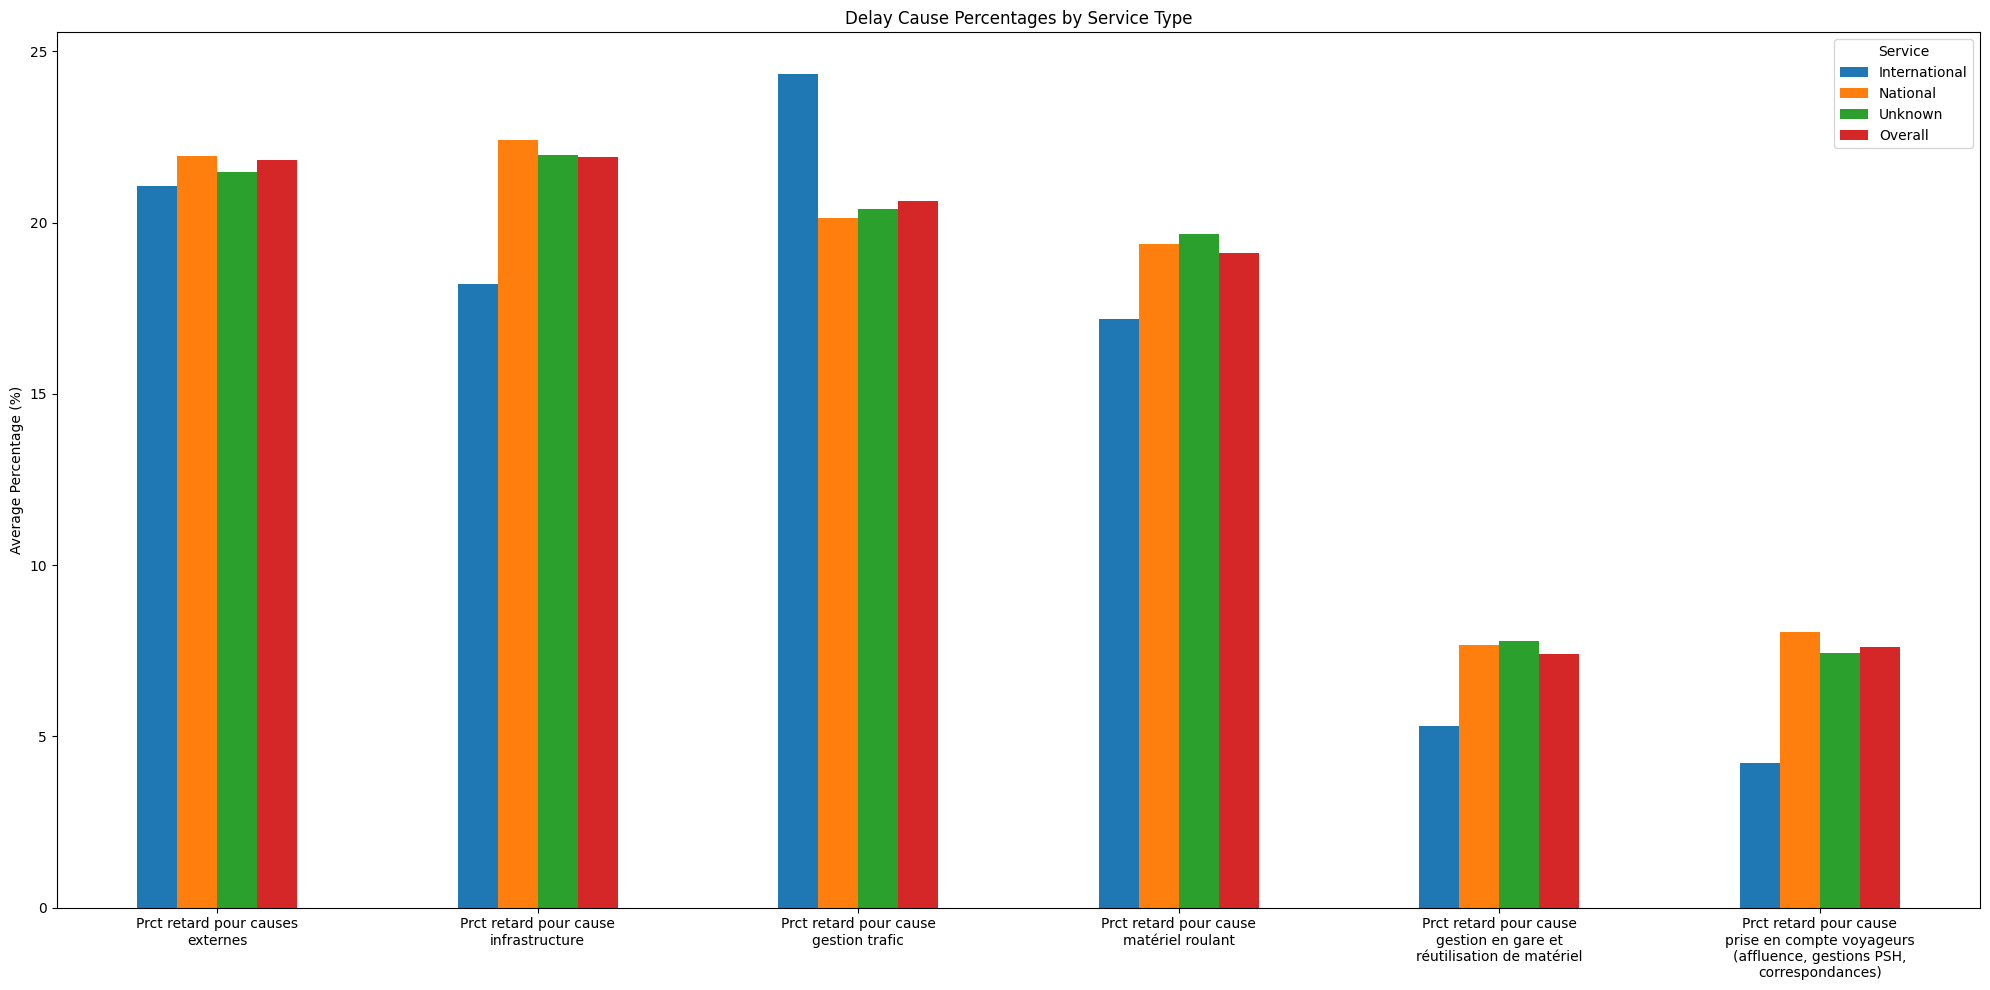

In [40]:
import textwrap

#select percentage columns and compute mean by service type
prct_cols = [col for col in df.columns if col.lower().startswith("prct")]
service_prct = df.groupby("Service")[prct_cols].mean()

#add overall average as an extra row
overall_prct = df[prct_cols].mean()
service_prct.loc["Overall"] = overall_prct

#create bar plot of transposed dataframe
plt.figure()

fg = service_prct.T.plot(kind="bar",figsize=(20,10))

#wrap long labels for readability
new_labels = [
    "\n".join(textwrap.wrap(label, 25))
    for label in service_prct.T.index]

fg.set_xticklabels(new_labels, rotation=0)

#plot formatting
plt.title("Delay Cause Percentages by Service Type")
plt.ylabel("Average Percentage (%)")
plt.tight_layout()
plt.show()

### Interpretation

Delay causes are broadly similar across National and International services.  
International services show a noticeably higher percentage of traffic management delays.  
Overall, differences exist but the general structure of delay causes remains consistent across service types.

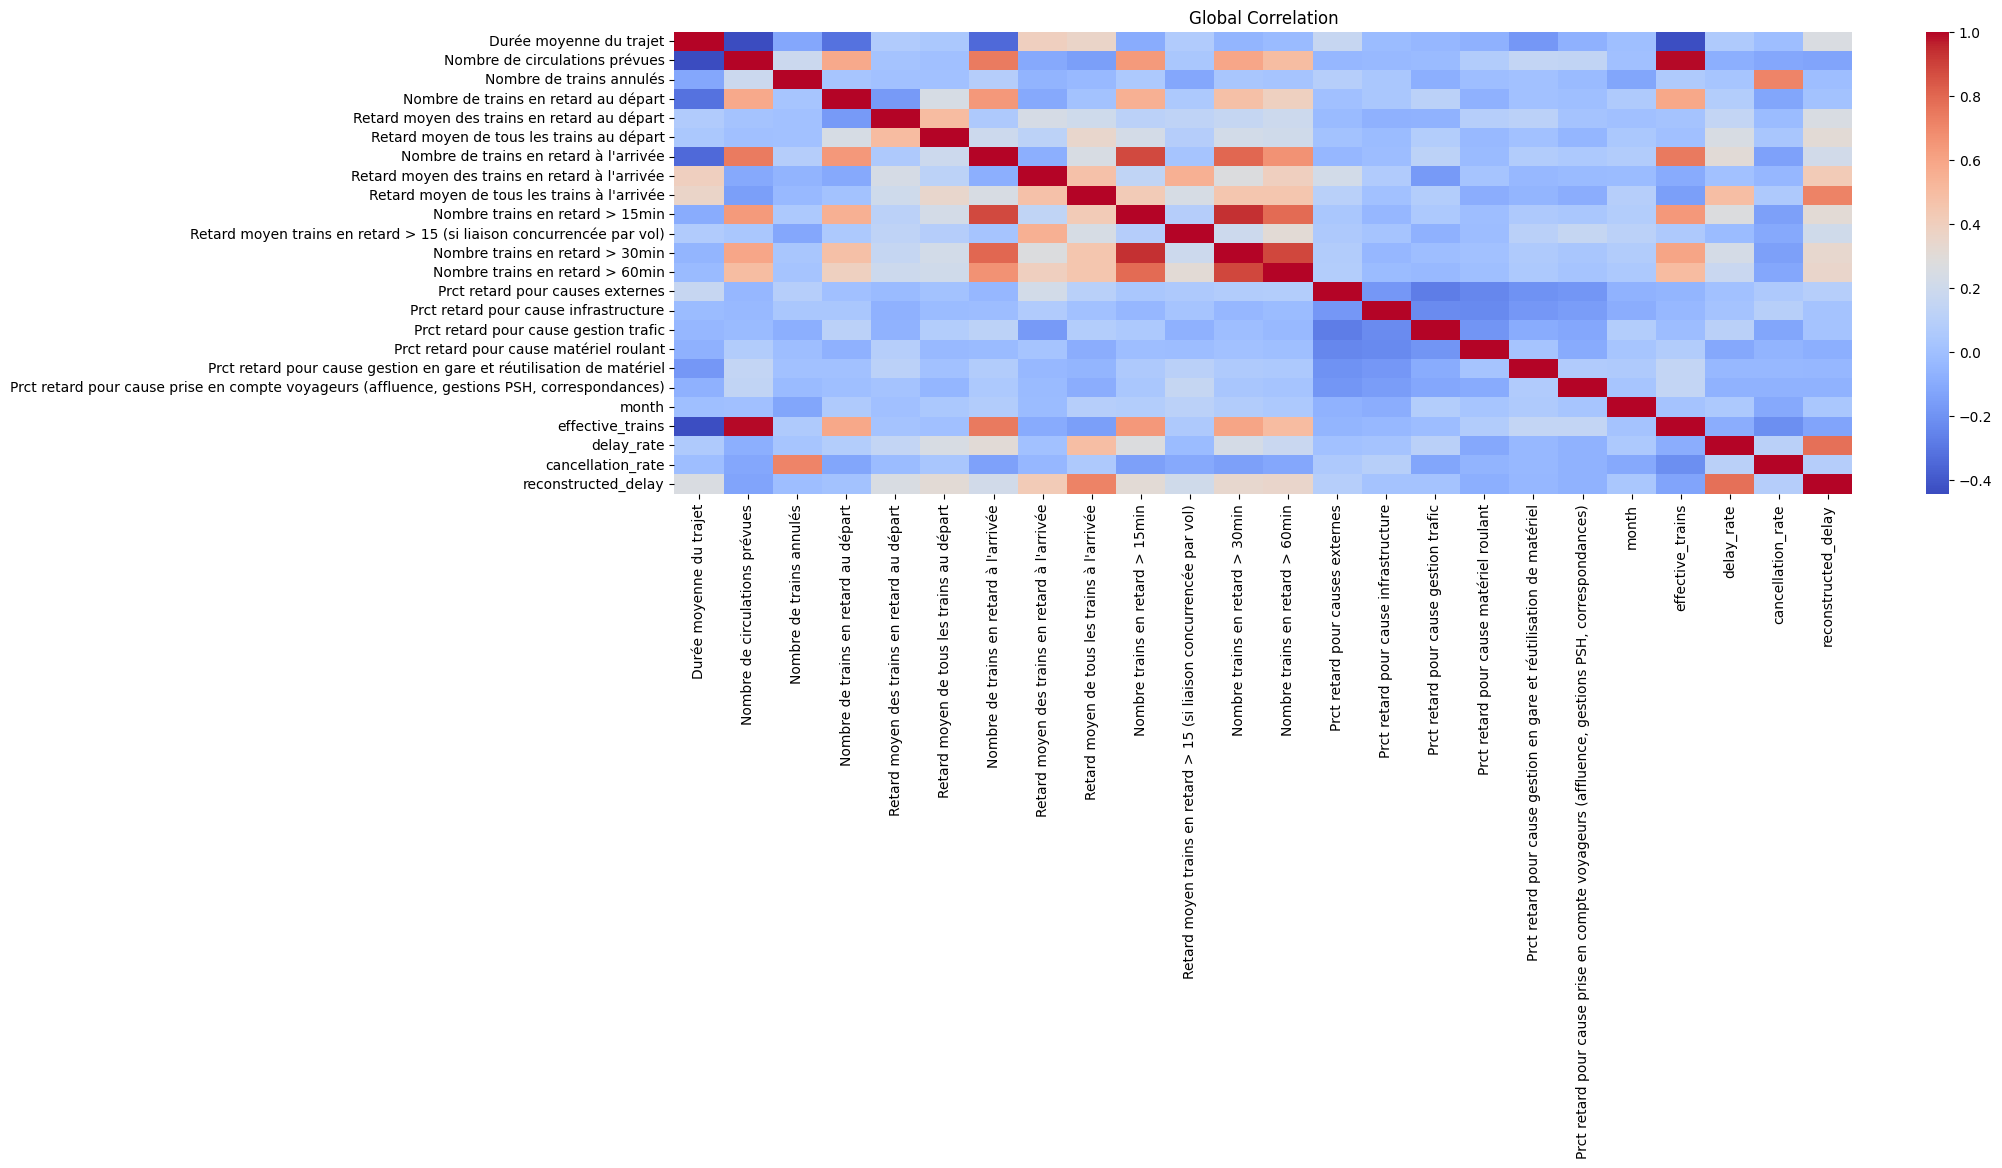

In [41]:
# compute effective trains and rate metrics
df["effective_trains"] = (df["Nombre de circulations prévues"] - df["Nombre de trains annulés"])

df["delay_rate"] = (df["Nombre de trains en retard à l'arrivée"] / df["effective_trains"])

df["cancellation_rate"] = (df["Nombre de trains annulés"] / df["Nombre de circulations prévues"])

# select numeric columns for correlation
numeric_cols = df.select_dtypes(include="number").columns

# plot global correlation heatmap
plt.figure(figsize=(19,6))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm")
plt.title("Global Correlation")
plt.show()

### Interpretation

The global correlation matrix is used as an exploratory tool to detect structural relationships and potentioal multicollinearity

In [42]:
# reconstruct overall delay from components
# delay_rate * mean delay among delayed trains
df["reconstructed_delay"] = (df["delay_rate"] * df["Retard moyen des trains en retard à l'arrivée"])

# check correlation with reported overall delay
df[["reconstructed_delay", "Retard moyen de tous les trains à l'arrivée"]].corr()

,reconstructed_delay,Retard moyen de tous les trains à l'arrivée
reconstructed_delay,1.000000,0.715598
Retard moyen de tous les trains à l'arrivée,0.715598,1.000000


### Interpretation

The strong correlation (r = 0.72) confirms that overall average delay is mainly driven by the delay rate and the mean delay among delayed trains, validating the internal coherence of the dataset.